# 08 — Scenarios and risk: prices, output, costs and timing drawn together

A book of leases and power requests fails together when oil collapses, gas spikes, the wind is weak and a plant arrives late. This notebook draws 2,000 reproducible joint scenarios for the forty candidates of notebook 07 — block-bootstrapped monthly joint shocks of WTI, Henry Hub and the ERCOT price (the correlations and the 2020 and 2022 episodes travel together) on prices that revert toward their 2018–2024 real means, output multipliers from the scored forecast residuals of notebook 05, cost multipliers from the grid, and operation years for the power requests from their curves from 1 January 2025 through the copula of the book simulation — values each candidate under every scenario, measures its risk (P(NPV < 0), VaR, CVaR) alone and in the book, runs the named stresses, builds a held-out set that redraws prices, output, costs and timing with its own seeds, which notebook 09 keeps out of sample, and removes the correlations to measure what they are worth. Where a candidate's data are thin (completeness below 1), its output uncertainty is widened by the inverse of its completeness (PLAN.md §14 addendum).

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/candidate_npv.csv`, `results/upstream_cost_grid.csv`, `results/candidate_capture_factors.csv` | notebook 07 part B: the forty candidates on 1 January 2025, with their operation curves from that date |
| in | `data/interim/market_monthly.parquet`, `data/interim/upstream_monthly.parquet` | notebook 01 |
| in | `data/processed/forecasts_holdout.parquet` | notebook 05 (scored residuals) |
| in | `results/book_rho.csv`, `results/atb_costs.csv`, `data/raw/prices/bls_CUUR0000SA0_*.json` | ρ from notebook 09 part A's book simulation (a committed registered result); ATB costs converted to 2024 dollars by the CPI-U |
| in | `data/raw/ercot/ercot_dam_spp_2024.parquet`, `data/raw/ercot/ercot_wind_solar_2024.parquet` | the 2024 hourly basis of the power candidates, as notebook 07 |
| out | `data/interim/scenario_prices_primary.npy`, `data/interim/scenario_prices_copula.npy` | price paths (scenarios × months × series), rebuilt by seed |
| out | `data/processed/candidate_npv_scenarios.parquet` | NPV of every candidate in every scenario: primary, held-out and independent (ablation) sets, merchant and contracted |
| out | `results/stress_candidates.csv` | NPV of every candidate under each named stress (for the stability test of notebook 09) |
| out | `results/scenario_settings.csv`, `results/scenario_price_bands.csv`, `results/scenario_correlation.csv` | the registered settings, the fan bands, the correlation check |
| out | `results/scenario_summary.csv`, `results/stress_tests.csv`, `results/correlation_ablation.csv`, `results/scenarios_checks.csv` | risk per candidate and per book; stresses; the ablation; checks |
| out | `figures/F30_price_scenarios.*`, `figures/F31_candidate_risk.*`, `figures/F32_stresses.*` | the pictures |
| out | `data/interim/scenario_state.npz` | the price paths and every output, cost and timing draw of both sets, for `src/whatif.py` (git-ignored) |

*Execution order:* runs after notebook 07.


## Setup

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, decision_date, economics as ec, energy_data, paths, plots, portfolio, scenarios as sc, valuation as va

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "08_scenarios_and_risk"
START = time.time()
R = paths.RESULTS
N_SCEN, HORIZON, BLOCK, SEED, LEVEL = 2000, 240, 12, 2020, 0.95  # registered settings (decision #69)
LIFE, HORIZON_YEARS = 20, 7
POWER_TECHS = {"Gas": "Gas CC", "Solar": "Solar", "Wind": "Wind", "Battery": "Storage"}


def save(fig, name, caption):
    """Save a figure of this notebook under figures/08_scenarios_and_risk/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    return f"{100 * x:.{digits}f}%"


book = pd.read_csv(R / "candidate_npv.csv")
grid = pd.read_csv(R / "upstream_cost_grid.csv").set_index("item")
capture = pd.read_csv(R / "candidate_capture_factors.csv").set_index("technology")
market = pd.read_parquet(paths.DATA_INTERIM / "market_monthly.parquet")
lease = decision_date.lease_history_on(pd.read_parquet(paths.DATA_INTERIM / "upstream_monthly.parquet"))  # the months BSEE had published on the decision date
forecasts = pd.read_parquet(paths.DATA_PROCESSED / "forecasts_holdout.parquet")
cpi = energy_data.read_cpi(sorted(paths.RAW_PRICES.glob(f"bls_{config.CPI_SERIES}_*.json"))[-1])
atb = va.atb_in_dollars_of(pd.read_csv(R / "atb_costs.csv").set_index("tech"), va.cpi_ratio(cpi, 2022, config.REAL_DOLLAR_YEAR))  # 2022 → 2024 dollars, as notebook 07 (audit E7)
rho_table = pd.read_csv(R / "book_rho.csv")
rho = float(rho_table.loc[rho_table.iloc[:, 0].astype(str).str.lower().str.contains("all|pooled|book"), "rho"].iloc[0]) if "rho" in rho_table.columns and rho_table.iloc[:, 0].astype(str).str.lower().str.contains("all|pooled|book").any() else float(rho_table["rho"].iloc[0]) if "rho" in rho_table.columns else 0.041
dam = pd.read_parquet(paths.RAW_ERCOT / "ercot_dam_spp_2024.parquet")
hub = dam[dam["Location"] == config.ERCOT_PRICE_HUB].set_index("Interval Start")["SPP"]
wind_solar = pd.read_parquet(paths.RAW_ERCOT / "ercot_wind_solar_2024.parquet")
m24 = market[market["month"].dt.year == 2024]
BASE = np.array([m24["wti_usd_bbl_real2024"].mean(), m24["hh_usd_mmbtu_real2024"].mean(), m24["ercot_usd_mwh_real2024"].mean()])
window = market[market["month"].between("2018-01-01", "2024-12-01")]
LONG_RUN = np.exp(np.log(window[["wti_usd_bbl_real2024", "hh_usd_mmbtu_real2024", "ercot_usd_mwh_real2024"]]).mean().to_numpy())  # OBSERVED 2018–2024 real geometric means: the model reverts in logs (decision #81)
HALF_LIFE = sc.HALF_LIFE_MONTHS  # ASSUMED four-year half-life of the reversion
leases = book[book["sector"] != "ERCOT power"].reset_index(drop=True)
power = book[book["sector"] == "ERCOT power"].reset_index(drop=True)
settings = pd.DataFrame([{"n_scenarios": N_SCEN, "horizon_months": HORIZON, "block_months": BLOCK, "seed_primary": SEED, "seed_copula": SEED + 1, "level": LEVEL,
                          "rho_book": rho, "base_wti": BASE[0], "base_hh": BASE[1], "base_ercot": BASE[2], "long_run_wti": LONG_RUN[0], "long_run_hh": LONG_RUN[1], "long_run_ercot": LONG_RUN[2],
                          "half_life_months": HALF_LIFE, "history": "2018-01 to 2024-12 monthly log changes (ERCOT 2020–2023 ASSUMED); shocks demeaned; mean reversion to the 2018–2024 real means"}])
settings.to_csv(R / "scenario_settings.csv", index=False)
print(f"{len(leases)} leases and {len(power)} requests; 2024 base WTI ${BASE[0]:.1f}, Henry Hub ${BASE[1]:.2f}, ERCOT ${BASE[2]:.1f}; "
      f"long-run (2018–2024 real geometric means) ${LONG_RUN[0]:.1f}, ${LONG_RUN[1]:.2f}, ${LONG_RUN[2]:.1f}; half-life {HALF_LIFE} months; ρ = {rho:.3f}")


20 leases and 20 requests; 2024 base WTI $76.6, Henry Hub $2.19, ERCOT $27.0; long-run (2018–2024 real geometric means) $74.1, $3.36, $38.9; half-life 48 months; ρ = 0.041


## 1. Joint price paths: bootstrapped shocks around a mean-reverting level, and the held-out draw

Monthly log changes of the three prices over 2018–2024 (83 months, every ERCOT month observed) are capped at ±1.5 (a ×4.5 move: Winter Storm Uri's +4.2 and −4.3 become an extreme month rather than a new level), resampled in calendar-year blocks, the same months for every series so that a spike and its reversal travel together, demeaned, and applied as shocks to a log price that reverts toward the 2018–2024 real geometric mean with a four-year half-life (ASSUMED; a twenty-year random walk of these changes would put WTI anywhere from $13 to $800 a barrel ten years out, which is not a planning case). The jumps and the cross-correlations are the history's; the drift and the unbounded variance are not. A second draw of the same generator with its own seed makes the held-out shock set that notebook 09 scores on and never selects on (a Gaussian copula with independent months was the held-out generator while the ERCOT months were a flat bridge; on the observed months it cannot keep a spike with its reversal, decision #82). The check: the simulated cross-correlations of the shocks against the historical ones.

In [2]:
changes = sc.joint_log_changes(market)
primary = sc.block_bootstrap_paths(changes, N_SCEN, HORIZON, block=BLOCK, seed=SEED)
copula = sc.block_bootstrap_paths(changes, N_SCEN, HORIZON, block=BLOCK, seed=SEED + 1)  # the held-out set: a second draw of the same generator (decision #82); the key 'copula' is kept in the files
prices_primary = sc.mean_reverting_prices(primary, BASE, LONG_RUN, HALF_LIFE)
prices_copula = sc.mean_reverting_prices(copula, BASE, LONG_RUN, HALF_LIFE)
np.save(paths.DATA_INTERIM / "scenario_prices_primary.npy", prices_primary)
np.save(paths.DATA_INTERIM / "scenario_prices_copula.npy", prices_copula)
names = ["WTI", "Henry Hub", "ERCOT"]
hist_corr = np.corrcoef(changes.T)
corr_rows = []
for label, paths_ in (("primary (block bootstrap)", primary), ("held-out (second block draw)", copula)):
    c = np.corrcoef(paths_.reshape(-1, 3).T)
    for i in range(3):
        for j in range(i + 1, 3):
            corr_rows.append({"generator": label, "pair": f"{names[i]}–{names[j]}", "historical": hist_corr[i, j], "simulated": c[i, j]})
corr_table = pd.DataFrame(corr_rows)
corr_table.to_csv(R / "scenario_correlation.csv", index=False)
years = np.arange(HORIZON) // 12 + 2025
bands = []
for k, name in enumerate(names):
    for y in range(2025, 2025 + HORIZON // 12):
        sel = prices_primary[:, years == y, k].mean(axis=1)
        bands.append({"series": name, "year": y, **{f"q{int(q * 100):02d}": float(np.quantile(sel, q)) for q in (0.05, 0.25, 0.5, 0.75, 0.95)}})
bands = pd.DataFrame(bands)
bands.to_csv(R / "scenario_price_bands.csv", index=False)
print(f"{N_SCEN} paths × {HORIZON} months; history {len(changes)} months; correlations historical vs primary: "
      + "; ".join(f"{r['pair']} {r['historical']:.2f}→{r['simulated']:.2f}" for _, r in corr_table[corr_table['generator'].str.startswith('primary')].iterrows())
      + f"; {time.time() - START:.0f} s")
corr_table.round(3)


2000 paths × 240 months; history 83 months; correlations historical vs primary: WTI–Henry Hub 0.06→0.06; WTI–ERCOT 0.03→0.03; Henry Hub–ERCOT 0.53→0.53; 1 s


,generator,pair,historical,simulated
0,primary (block bootstrap),WTI–Henry Hub,0.060,0.061
1,primary (block bootstrap),WTI–ERCOT,0.025,0.025
2,primary (block bootstrap),Henry Hub–ERCOT,0.526,0.533
3,held-out (second block draw),WTI–Henry Hub,0.060,0.062
4,held-out (second block draw),WTI–ERCOT,0.025,0.025
5,held-out (second block draw),Henry Hub–ERCOT,0.526,0.533


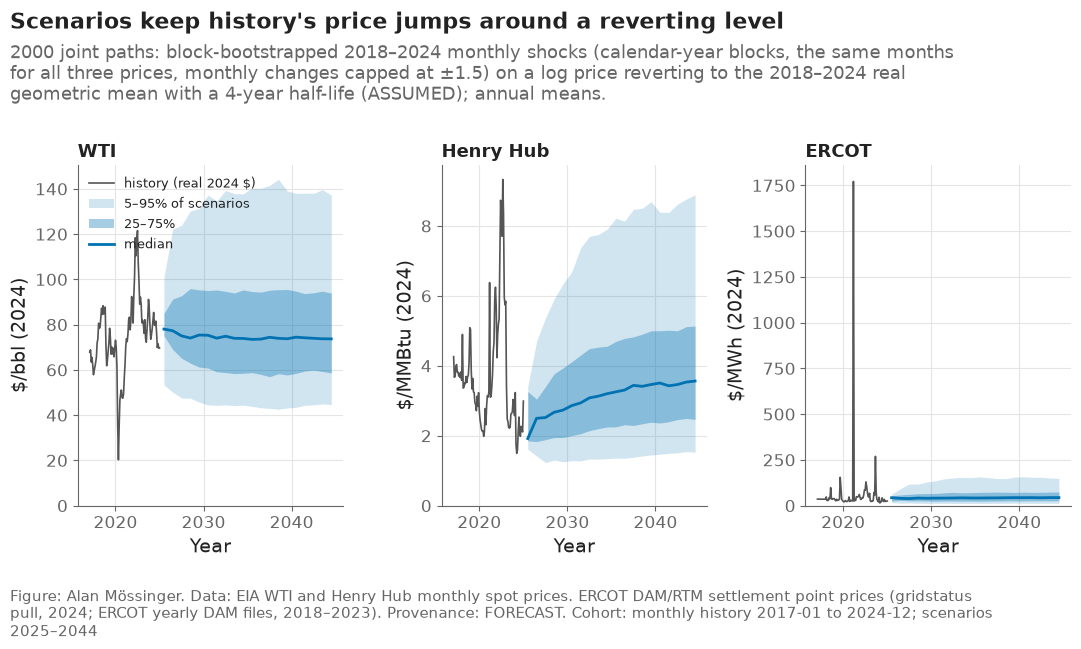

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5))
hist = market.set_index("month")
hist_cols = ["wti_usd_bbl_real2024", "hh_usd_mmbtu_real2024", "ercot_usd_mwh_real2024"]
units = ["$/bbl (2024)", "$/MMBtu (2024)", "$/MWh (2024)"]
for ax, name, col, unit in zip(axes, names, hist_cols, units):
    b = bands[bands["series"] == name]
    ax.plot(hist.index.year + hist.index.month / 12, hist[col], color="#555555", lw=1.2, label="history (real 2024 $)")
    ax.fill_between(b["year"] + 0.5, b["q05"], b["q95"], color="#0072B2", alpha=0.18, label="5–95% of scenarios")
    ax.fill_between(b["year"] + 0.5, b["q25"], b["q75"], color="#0072B2", alpha=0.35, label="25–75%")
    ax.plot(b["year"] + 0.5, b["q50"], color="#0072B2", lw=2, label="median")
    ax.set_title(name, fontsize=13)
    ax.set_ylabel(unit)
    ax.set_xlabel("Year")
    ax.set_ylim(0, None)
axes[0].legend(loc="upper left", fontsize=9)
wti_b = bands[(bands["series"] == "WTI") & (bands["year"] == 2034)].iloc[0]
plots.finish(fig,
             f"Ten years out the scenarios put WTI between \${wti_b['q05']:.0f} and \${wti_b['q95']:.0f} a barrel (5–95%): the history's own jumps around a level that reverts to the 2018–2024 mean",
             f"{N_SCEN} joint paths: block-bootstrapped 2018–2024 monthly shocks (calendar-year blocks, the same months for all three prices, monthly changes capped at ±{sc.MAX_MONTHLY_LOG_CHANGE:g}) on a log price reverting to the 2018–2024 real geometric mean with a {HALF_LIFE // 12}-year half-life (ASSUMED); annual means.",
             "monthly history 2017-01 to 2024-12; scenarios 2025–2044", lbnl=False, sources=[config.SOURCE_EIA_PRICES, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F30_price_scenarios", "Fan of the joint price scenarios against the real-dollar history for WTI, Henry Hub and ERCOT.", NOTEBOOK)
plt.show()


**Reading this.** Ten years out the scenarios put WTI between $44 and $138 a barrel (5–95%, F30), around a level that reverts toward the 2018–2024 real mean of $74.1, close to the 2024 base of $76.6; the reversion has a four-year half-life (ASSUMED), so the fans widen for a few years and then settle. Gas and power are a different case: their 2024 prices ($2.19/MMBtu and $27.0/MWh) sit well below their 2018–2024 means ($3.36 and $38.9), so their median paths rise toward those means. That rise, not a forecast of scarcity, is what lifts the power requests' scenario values above their flat-path values in section 4. The cross-correlations of the shocks survive the resampling (Henry Hub–ERCOT 0.53 against 0.53 historical, WTI–Henry Hub 0.06, WTI–ERCOT 0.03, in both sets). A block of twelve months keeps a year of 2020 or 2022 intact, so the set contains collapses and spikes of the shape the market produced; the same choice means seven historical years make every path, and there is no joint oil–power tail beyond what 2018–2024 contained.

## 2. Output, cost and timing draws

Output multipliers come from the scored holdout forecasts, one ratio per lease or plant: its actual output summed over its scored holdout months over the forecast summed over the same months (leases: the post-hoc level model labelled in notebook 05; plants: the registered challengers), bounded to [0.2, 3]; one draw per candidate per scenario, the lease draw weighted by the lease's forecast volume (a multiplier for a deepwater candidate comes from large producers' errors, not from the tail of small leases), the deviation from 1 widened by 1/completeness. A month-level ratio would mix shut-in months with producing ones and say nothing about a year. Costs move together by a triangular multiplier on the workover and operating cost (0.75–1.5, mode 1, ASSUMED). Operation years for the twenty requests come from the 1 January 2025 curves through the book simulation's copula with ρ = 0.041 (a draw of 0 is a request that never operates within seven years).

In [4]:
lease_ratios, lease_weights = sc.key_level_ratios(forecasts, "lease_oil_h3", pred_column="pred_level_posthoc", return_weights=True)  # one ratio per lease, weighted by its volume
cf_ratios = {t: sc.key_level_ratios(forecasts, f"cf_{t}_h1", pred_column="pred") for t in ("Solar", "Wind", "Gas CC")}  # one per plant
out_lease = sc.draw_multipliers(lease_ratios, N_SCEN, len(leases), seed=SEED + 10, weights=lease_weights)
out_lease = 1 + (out_lease - 1) / leases["data_completeness"].to_numpy()[None, :]
out_power = np.ones((N_SCEN, len(power)))
for j, r in power.iterrows():
    key = {"Solar": "Solar", "Wind": "Wind", "Gas CC": "Gas CC"}.get(r["technology"])
    if key:
        out_power[:, j] = sc.draw_multipliers(cf_ratios[key], N_SCEN, 1, seed=SEED + 20 + j)[:, 0]
cost_mult = sc.cost_multipliers(N_SCEN, seed=SEED + 30)
P = power[[f"p_op_{h}" for h in range(1, HORIZON_YEARS + 1)]].to_numpy(float)  # P(operation by year j from 1 January 2025), notebook 07
op_year = portfolio.simulate_operation_years(P, power["technology"].to_numpy(), rho, n_draws=N_SCEN, seed=SEED + 40)
# the held-out set draws every component again with its own seeds: in v7 only its prices were redrawn (audit A7)
HELD_OUT = 1000
out_lease_h = 1 + (sc.draw_multipliers(lease_ratios, N_SCEN, len(leases), seed=SEED + HELD_OUT + 10, weights=lease_weights) - 1) / leases["data_completeness"].to_numpy()[None, :]
out_power_h = np.ones((N_SCEN, len(power)))
for j, r in power.iterrows():
    key = {"Solar": "Solar", "Wind": "Wind", "Gas CC": "Gas CC"}.get(r["technology"])
    if key:
        out_power_h[:, j] = sc.draw_multipliers(cf_ratios[key], N_SCEN, 1, seed=SEED + HELD_OUT + 20 + j)[:, 0]
cost_mult_h = sc.cost_multipliers(N_SCEN, seed=SEED + HELD_OUT + 30)
op_year_h = portfolio.simulate_operation_years(P, power["technology"].to_numpy(), rho, n_draws=N_SCEN, seed=SEED + HELD_OUT + 40)
draw_summary = pd.DataFrame([
    {"draw": "lease output multiplier (per lease, scored months summed, volume-weighted draw)", "n_source_rows": len(lease_ratios), "mean": out_lease.mean(), "sd": out_lease.std(), "provenance": "FORECAST residuals (post-hoc level model), widened by 1/completeness"},
    {"draw": "solar/wind CF multiplier (per plant)", "n_source_rows": sum(len(v) for v in cf_ratios.values()), "mean": out_power[:, power['technology'].isin(['Solar', 'Wind']).to_numpy()].mean(), "sd": out_power[:, power['technology'].isin(['Solar', 'Wind']).to_numpy()].std(), "provenance": "FORECAST residuals"},
    {"draw": "cost multiplier", "n_source_rows": 0, "mean": cost_mult.mean(), "sd": cost_mult.std(), "provenance": "ASSUMED triangular 0.75–1.5"},
    {"draw": "share of requests never operating within 7 y", "n_source_rows": len(power), "mean": float((op_year == 0).mean()), "sd": np.nan, "provenance": "FORECAST (queue models) through the ρ copula"},
])
draw_summary.to_csv(R / "scenario_draws.csv", index=False)
print(f"timing: mean P(operation by 7 y) {P[:, -1].mean():.2f}; simulated share never operating {(op_year == 0).mean():.2f}; {time.time() - START:.0f} s")
draw_summary.round(3)


timing: mean P(operation by 7 y) 0.10; simulated share never operating 0.90; 3 s


,draw,n_source_rows,mean,sd,provenance
0,"lease output multiplier (per lease, scored mon...",1040,0.995,0.263,"FORECAST residuals (post-hoc level model), wid..."
1,solar/wind CF multiplier (per plant),415,0.980,0.238,FORECAST residuals
2,cost multiplier,0,1.084,0.161,ASSUMED triangular 0.75–1.5
3,share of requests never operating within 7 y,20,0.903,NaN,FORECAST (queue models) through the ρ copula


## 3. Every candidate under every scenario

Leases: the Arps baseline times the output multiplier, the scenario's WTI and Henry Hub paths, the cost multiplier on workover and operating cost, incremental NPV against doing nothing. Requests: the NPV if built, with its revenue scaled by the scenario's mean real ERCOT price over the plant's life relative to the 2024 base and by the capacity-factor multiplier, its fuel by the Henry Hub ratio, discounted from the drawn operation year; minus the cost to carry; −cost to carry when the request never operates. Both generators, merchant and contracted.

In [5]:
oil_w = lease.pivot(index="lease_number", columns="month", values="oil_bbl").fillna(0)
gas_w = lease.pivot(index="lease_number", columns="month", values="gas_mcf").fillna(0)
baselines = []
for _, r in leases.iterrows():
    lid = r["project_id"].split("|")[1]
    bo, bg, _, _ = decision_date.lease_baseline_on(oil_w.loc[lid].to_numpy(), gas_w.loc[lid].to_numpy(), months=HORIZON)
    baselines.append((bo, bg))
wells = leases["n_wells"].astype(int).to_numpy()
g_base = ec.grid_case("base")
basis = va.basis_2024(hub, wind_solar["solar_mw"], wind_solar["wind_mw"], atb, BASE[1])  # the same 2024 basis as notebook 07
components = {t: va.pv_components(va.TECH_OF[t], atb, basis, BASE[2], BASE[1]) for t in power["technology"].unique()}


def lease_npvs(prices, out_mult, cost_mult_):
    """Incremental NPV of every lease in every scenario (``valuation.lease_npv_matrix``)."""
    return va.lease_npv_matrix(baselines, wells, prices, out_mult, cost_mult_, g_base)


def power_npvs(prices, out_mult, op_year_, case="merchant"):
    """NPV of every request in every scenario (``valuation.power_npv_matrix``)."""
    return va.power_npv_matrix(power, components, prices, out_mult, op_year_, BASE, HORIZON, case)


t0 = time.time()
npv_sets = {}
draws = {"primary": (out_lease, cost_mult, out_power, op_year), "copula": (out_lease_h, cost_mult_h, out_power_h, op_year_h)}
for gen_name, prices in (("primary", prices_primary), ("copula", prices_copula)):
    ol, cm, op_, oy = draws[gen_name]
    L = lease_npvs(prices, ol, cm)
    for case in ("merchant", "contracted"):
        Pw = power_npvs(prices, op_, oy, case)
        npv_sets[(gen_name, case)] = np.concatenate([L, Pw], axis=1)
ids = list(leases["project_id"]) + list(power["project_id"])
long = pd.concat([pd.DataFrame(arr, columns=ids).assign(scenario=np.arange(N_SCEN), generator=g, revenue_case=c)
                  for (g, c), arr in npv_sets.items()], ignore_index=True)
long.to_parquet(paths.DATA_PROCESSED / "candidate_npv_scenarios.parquet", index=False)
np.savez_compressed(paths.DATA_INTERIM / "scenario_state.npz", prices=prices_primary, out_lease=out_lease, cost_mult=cost_mult, out_power=out_power, op_year=op_year,
                    prices_h=prices_copula, out_lease_h=out_lease_h, cost_mult_h=cost_mult_h, out_power_h=out_power_h, op_year_h=op_year_h)  # every draw, for src/whatif.py
print(f"{len(npv_sets)} scenario sets × {N_SCEN} scenarios × {len(ids)} candidates in {time.time() - t0:.0f} s")


4 scenario sets × 2000 scenarios × 40 candidates in 28 s


## 4. Risk per candidate and per book

P(NPV < 0), the 5% value at risk and the expected shortfall below it (CVaR 95%), for every candidate and for the default book, under the primary generator in both revenue cases, with the held-out set beside it.

In [6]:
rows = []
for (g, c), arr in npv_sets.items():
    for j, pid in enumerate(ids):
        rows.append({"generator": g, "revenue_case": c, "project_id": pid, "sector": book.set_index("project_id").loc[pid, "sector"],
                     "technology": book.set_index("project_id").loc[pid, "technology"], **sc.risk_measures(arr[:, j], LEVEL)})
    rows.append({"generator": g, "revenue_case": c, "project_id": "BOOK (default 40)", "sector": "book", "technology": "", **sc.risk_measures(arr.sum(axis=1), LEVEL)})
    rows.append({"generator": g, "revenue_case": c, "project_id": "BOOK leases only", "sector": "book", "technology": "", **sc.risk_measures(arr[:, : len(leases)].sum(axis=1), LEVEL)})
    rows.append({"generator": g, "revenue_case": c, "project_id": "BOOK power only", "sector": "book", "technology": "", **sc.risk_measures(arr[:, len(leases):].sum(axis=1), LEVEL)})
summary = pd.DataFrame(rows)
summary.to_csv(R / "scenario_summary.csv", index=False)
bk = summary[(summary["generator"] == "primary") & (summary["project_id"] == "BOOK (default 40)")].set_index("revenue_case")
print(f"default book, primary scenarios: merchant mean ${bk.loc['merchant', 'mean'] / 1e9:.2f}B, P(NPV<0) {pct(bk.loc['merchant', 'p_negative'])}, VaR95 ${bk.loc['merchant', 'var'] / 1e9:.2f}B, CVaR95 ${bk.loc['merchant', 'cvar'] / 1e9:.2f}B; "
      f"contracted mean ${bk.loc['contracted', 'mean'] / 1e9:.2f}B, CVaR95 ${bk.loc['contracted', 'cvar'] / 1e9:.2f}B")
summary[(summary["generator"] == "primary") & (summary["revenue_case"] == "merchant") & (summary["sector"] != "book")].sort_values("cvar")[["project_id", "technology", "mean", "p_negative", "var", "cvar"]].round(0).head(12)


default book, primary scenarios: merchant mean $9.80B, P(NPV<0) 0.8%, VaR95 $2.56B, CVaR95 $1.30B; contracted mean $10.14B, CVaR95 $2.33B


,project_id,technology,mean,p_negative,var,cvar
21,REQ|ERCOT|25INR0008,Gas CC,512280039.0,1.0,-869614284.0,-1.350375e+09
24,REQ|ERCOT|26INR0155,Solar,13123986.0,1.0,-635789969.0,-8.334629e+08
20,REQ|ERCOT|24INR0075,Solar,-4080425.0,1.0,-401491606.0,-6.792927e+08
22,REQ|ERCOT|26INR0046,Solar,4864091.0,1.0,-62586363.0,-4.818992e+08
31,REQ|ERCOT|27INR0071,Gas CC,121226177.0,1.0,-1063791.0,-4.635330e+08
33,REQ|ERCOT|27INR0221,Solar,5255604.0,1.0,-153214716.0,-4.434497e+08
38,REQ|ERCOT|29INR0003,Solar,10732968.0,1.0,-945914.0,-3.590040e+08
23,REQ|ERCOT|26INR0113,Wind,244292053.0,1.0,-98511189.0,-3.302165e+08
32,REQ|ERCOT|27INR0084,Gas CC,50384300.0,1.0,-1292697.0,-2.967890e+08
25,REQ|ERCOT|26INR0261,Gas CC,87010804.0,1.0,-928884.0,-2.850898e+08


C:\Users\alanm\AppData\Local\Temp\ipykernel_30116\3987236268.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(data_l, vert=False, showfliers=False, widths=0.6, medianprops={"color": plots.INK})
C:\Users\alanm\AppData\Local\Temp\ipykernel_30116\3987236268.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = axes[1].boxplot(data_p, vert=False, showfliers=False, widths=0.6, patch_artist=True, medianprops={"color": plots.INK})


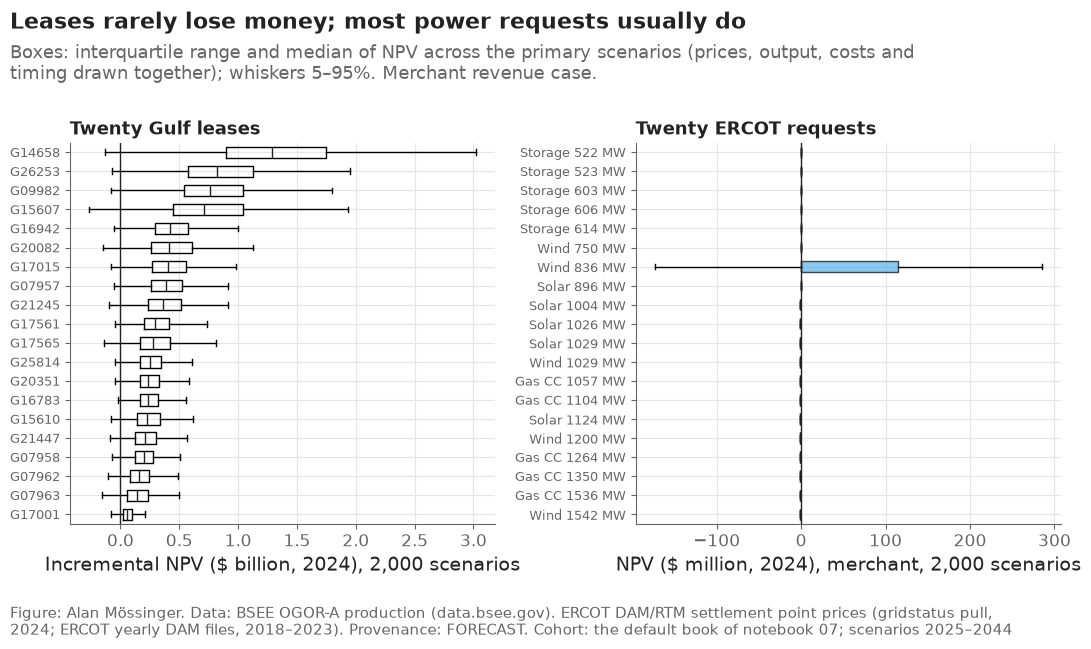

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1, 1]})
arr = npv_sets[("primary", "merchant")]
order_l = np.argsort(np.median(arr[:, : len(leases)], axis=0))
data_l = [arr[:, j] / 1e9 for j in order_l]
axes[0].boxplot(data_l, vert=False, showfliers=False, widths=0.6, medianprops={"color": plots.INK})
axes[0].set_yticks(np.arange(1, len(leases) + 1), [leases.loc[j, "project_id"].split("|")[1] for j in order_l], fontsize=9)
axes[0].axvline(0, color=plots.INK, lw=1)
axes[0].set_xlabel("Incremental NPV ($ billion, 2024), 2,000 scenarios")
axes[0].set_title("Twenty Gulf leases", fontsize=13)
order_p = np.argsort(np.median(arr[:, len(leases):], axis=0))
data_p = [arr[:, len(leases) + j] / 1e6 for j in order_p]
bp = axes[1].boxplot(data_p, vert=False, showfliers=False, widths=0.6, patch_artist=True, medianprops={"color": plots.INK})
for patch, j in zip(bp["boxes"], order_p):
    patch.set_facecolor({"Gas CC": config.TECH_COLORS["Gas"], "Solar": config.TECH_COLORS["Solar"], "Wind": config.TECH_COLORS["Wind"], "Storage": config.TECH_COLORS["Battery"]}[power.loc[j, "technology"]])
    patch.set_alpha(0.7)
axes[1].set_yticks(np.arange(1, len(power) + 1), [f"{power.loc[j, 'technology']} {power.loc[j, 'mw']:.0f} MW" for j in order_p], fontsize=9)
axes[1].axvline(0, color=plots.INK, lw=1)
axes[1].set_xlabel("NPV ($ million, 2024), merchant, 2,000 scenarios")
axes[1].set_title("Twenty ERCOT requests", fontsize=13)
neg = summary[(summary["generator"] == "primary") & (summary["revenue_case"] == "merchant") & (summary["sector"] != "book")]
n_risky_leases = int((neg[neg["sector"] != "ERCOT power"]["p_negative"] > 0.05).sum())
n_neg_power = int((neg[neg["sector"] == "ERCOT power"]["p_negative"] > 0.5).sum())
cvar_b = bk.loc["merchant", "cvar"] / 1e9
title = (f"Under joint scenarios {n_risky_leases} of 20 leases lose money in more than one scenario in twenty and {n_neg_power} of 20 ERCOT requests lose in most; "
         + (f"the book's CVaR95 is \${cvar_b:.1f}B" if cvar_b >= 0 else f"the book's 5% shortfall averages \${-cvar_b:.1f}B below zero"))
plots.finish(fig, title,
             "Boxes: interquartile range and median of NPV across the primary scenarios (prices, output, costs and timing drawn together); whiskers 5–95%. Merchant revenue case.",
             "the default book of notebook 07; scenarios 2025–2044", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="FORECAST")
plots.save_fig(fig, "F31_candidate_risk", "NPV distributions of the forty candidates under the joint scenarios, merchant case.", NOTEBOOK)
plt.show()


**Reading this.** On the joint scenarios the default book averages $9.80 billion at merchant prices and $10.14 billion under contract, against $7.09 billion on the flat path of notebook 07; it loses money in 0.8% of scenarios, and its worst 5% still average a $1.30 billion profit (CVaR95; $2.33 billion under contract). The gap to the flat path comes from the skew of the price paths and from gas and ERCOT prices reverting up from their low 2024 levels. By candidate the picture splits in two (F31). Three of the twenty leases lose money in more than one scenario in twenty; the rest in one in twenty or fewer, though their boxes are wide because oil moves and the output draw is wide. All twenty requests lose money in most scenarios, because in 90% of draws a request never operates within seven years and costs exactly its carry. Several still have a positive mean: the 1,350 MW gas plant averages +$512 million and loses money in 77% of scenarios; the agreement-backed 836 MW wind request averages +$244 million and loses in 73%. The few scenarios in which they are built carry the higher reverting prices. For a developer that is the shape of an option, not of an asset: a likely small loss and a rare large gain. The tail of each request (CVaR95 of −$0.14 billion to −$1.35 billion for the twelve shown) is the outcome in which the plant is built and prices stay low. This is what the optimizer of notebook 09 sees: the leases are the return, and the requests are options whose value rests on the price level the scenarios assume.

## 5. Named stresses

Deterministic what-ifs on the base case: WTI follows its 2020 path from the first month; Henry Hub +50%; a weak wind year (−15% capacity factor); solar curtailment (−10% revenue); a two-year delay for every request; and all of them at once with costs +20%. Each is a multiplier the report states, not a probability.

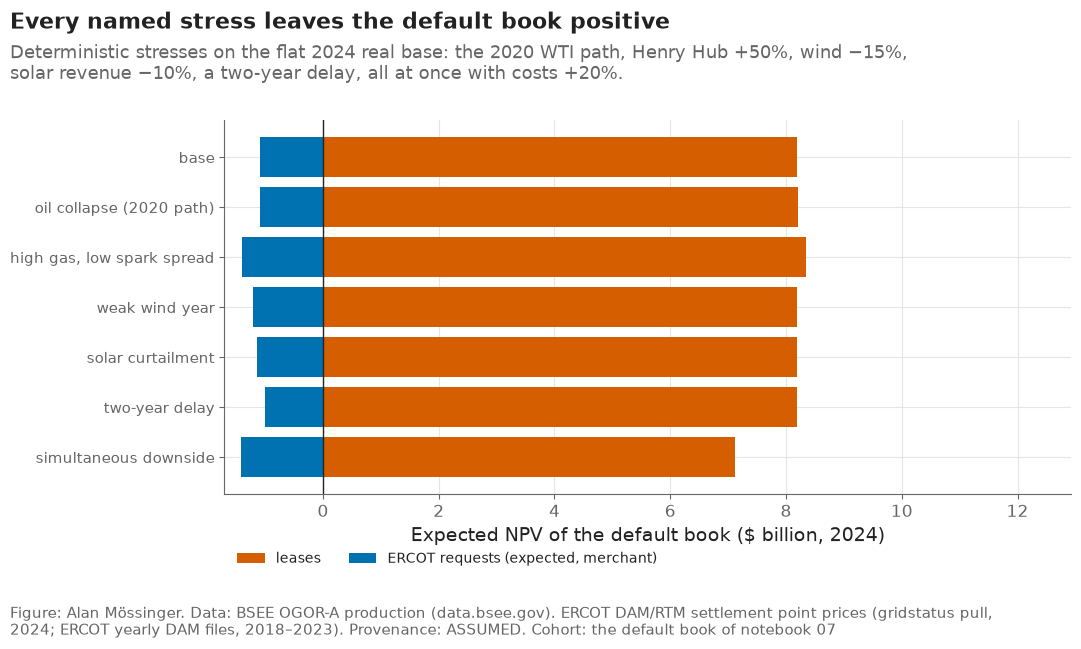

,stress,book_npv_leases,book_npv_power,book_npv,change_vs_base
0,base,8.187000e+09,-1.093000e+09,7.094000e+09,0.000000e+00
1,oil collapse (2020 path),8.207000e+09,-1.093000e+09,7.115000e+09,2.000000e+07
2,"high gas, low spark spread",8.338000e+09,-1.396000e+09,6.942000e+09,-1.520000e+08
3,weak wind year,8.187000e+09,-1.204000e+09,6.983000e+09,-1.110000e+08
4,solar curtailment,8.187000e+09,-1.143000e+09,7.043000e+09,-5.100000e+07
5,two-year delay,8.187000e+09,-9.980000e+08,7.189000e+09,9.500000e+07
6,simultaneous downside,7.111000e+09,-1.419000e+09,5.693000e+09,-1.401000e+09


In [8]:
wti_2020 = market.set_index("month").loc["2019-12-01":"2021-12-01", "wti_usd_bbl_real2024"].to_numpy()
wti_2020 = wti_2020 * BASE[0] / wti_2020[0]  # the 2020 shape, started from the base level
flat = np.ones((1, HORIZON, 3)) * BASE[None, None, :]
stress_rows, stress_candidate_rows = [], []
for name, stress in sc.STRESSES.items():
    prices = sc.stress_prices(flat[0], stress, wti_2020_path=wti_2020)[None, :, :]
    cost = np.array([stress.get("cost", 1.0)])
    outl = np.ones((1, len(leases)))
    L = lease_npvs(prices, outl, cost)
    outp = np.ones((1, len(power)))
    if "wind_cf" in stress:
        outp[0, power["technology"].eq("Wind").to_numpy()] = stress["wind_cf"]
    if "solar_revenue" in stress:
        outp[0, power["technology"].eq("Solar").to_numpy()] = stress["solar_revenue"]
    # timing: expected value over the entry curve, shifted by the delay
    delay = stress.get("delay_years", 0)
    exp_power = np.zeros(len(power))
    for j, r in power.iterrows():
        curve = P[j]
        inc = np.diff(np.concatenate([[0.0], curve]))
        val = 0.0
        for y in range(1, HORIZON_YEARS + 1):
            oy = np.zeros((1, len(power)), int)  # one column per request; only column j is read
            oy[0, j] = y + delay
            val += inc[y - 1] * power_npvs(prices, outp, oy, "merchant")[0, j]
        exp_power[j] = val - (1 - curve[-1]) * r["carry_cost"]  # the share that never operates costs its carry
    stress_rows.append({"stress": name, "book_npv_leases": float(L.sum()), "book_npv_power": float(exp_power.sum()), "book_npv": float(L.sum() + exp_power.sum()), **{k: str(v) for k, v in stress.items()}})
    stress_candidate_rows += [{"stress": name, "project_id": pid, "npv": float(v)} for pid, v in zip(list(leases["project_id"]) + list(power["project_id"]), np.concatenate([L[0], exp_power]))]
stresses = pd.DataFrame(stress_rows)
stress_candidates = pd.DataFrame(stress_candidate_rows)
stress_candidates.to_csv(R / "stress_candidates.csv", index=False)
stresses["change_vs_base"] = stresses["book_npv"] - stresses.loc[0, "book_npv"]
stresses.to_csv(R / "stress_tests.csv", index=False)
fig, ax = plt.subplots(figsize=(11, 6.5))
y = np.arange(len(stresses))
ax.barh(y, stresses["book_npv_leases"] / 1e9, color="#D55E00", label="leases")
ax.barh(y, stresses["book_npv_power"] / 1e9, left=np.minimum(stresses["book_npv_leases"] / 1e9, 0), color="#0072B2", label="ERCOT requests (expected, merchant)")
ax.set_yticks(y, stresses["stress"], fontsize=10.5)
ax.invert_yaxis()
ax.axvline(0, color=plots.INK, lw=1)
ax.set_xlabel("Expected NPV of the default book ($ billion, 2024)")
ax.set_xlim(min(0, stresses["book_npv_power"].min() / 1e9 * 1.2), stresses["book_npv_leases"].max() / 1e9 * 1.55)
ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.12), ncol=2, fontsize=10, frameon=False)  # below the axis: the bars fill the panel
worst = stresses.sort_values("book_npv").iloc[0]
plots.finish(fig,
             (f"The book keeps a positive expected NPV in every named stress; the worst, '{worst['stress']}', takes it to \${worst['book_npv'] / 1e9:.1f}B from \${stresses.loc[0, 'book_npv'] / 1e9:.1f}B"
              if worst["book_npv"] > 0 else f"The stress '{worst['stress']}' takes the book's expected NPV below zero, to \${worst['book_npv'] / 1e9:.1f}B from \${stresses.loc[0, 'book_npv'] / 1e9:.1f}B"),
             "Deterministic stresses on the flat 2024 real base: the 2020 WTI path, Henry Hub +50%, wind −15%, solar revenue −10%, a two-year delay, all at once with costs +20%.",
             "the default book of notebook 07", lbnl=False, sources=[config.SOURCE_BSEE, config.SOURCE_ERCOT], provenance="ASSUMED")
plots.save_fig(fig, "F32_stresses", "Expected NPV of the default book under each named stress, leases and requests separately.", NOTEBOOK)
plt.show()
stresses[["stress", "book_npv_leases", "book_npv_power", "book_npv", "change_vs_base"]].round(-6)


**Reading this.** The book keeps a positive expected NPV in every named stress, and only all of them at once moves it much: from $7.09 billion to $5.69 billion, with the leases falling from $8.19 billion to $7.11 billion and the requests from −$1.09 billion to −$1.42 billion. One at a time the stresses are small. The 2020 oil path changes the book by +$20 million, because the collapse and the recovery are over before the incremental barrels start at month 24. High gas raises the leases to $8.34 billion on their gas and lowers the requests to −$1.40 billion, a net −$152 million. A weak wind year costs the requests $111 million and solar curtailment $51 million. A two-year delay *raises* the book by $95 million: at flat 2024 merchant prices a built plant loses money, and with the credits no longer expiring (decision #94) a delay only pushes that loss further out. That is a statement about the flat path, not a reason to want delay. For a committee the lesson is about what these stresses do not test: a sustained low oil price, which is what hurts a book of oil redevelopments. Notebook 09 part E adds one (five years at $42).

## 6. What the correlations are worth

The same bootstrap with each series resampled on its own (correlations removed, marginals kept): the book's CVaR with and without the co-movement of oil, gas and power. A diversification benefit that only exists when the correlations are ignored is not a benefit.

In [9]:
indep = np.stack([sc.block_bootstrap_paths(changes[:, [k]], N_SCEN, HORIZON, block=BLOCK, seed=SEED + 100 + k)[:, :, 0] for k in range(3)], axis=2)
prices_indep = sc.mean_reverting_prices(indep, BASE, LONG_RUN, HALF_LIFE)
L_ind = lease_npvs(prices_indep, out_lease, cost_mult)
P_ind = power_npvs(prices_indep, out_power, op_year, "merchant")
indep_all = np.concatenate([L_ind, P_ind], axis=1)
P_ind_c = power_npvs(prices_indep, out_power, op_year, "contracted")
long_ind = pd.concat([pd.DataFrame(indep_all, columns=ids).assign(scenario=np.arange(N_SCEN), generator="independent", revenue_case="merchant"),
                      pd.DataFrame(np.concatenate([L_ind, P_ind_c], axis=1), columns=ids).assign(scenario=np.arange(N_SCEN), generator="independent", revenue_case="contracted")], ignore_index=True)
pd.concat([long, long_ind], ignore_index=True).to_parquet(paths.DATA_PROCESSED / "candidate_npv_scenarios.parquet", index=False)
joint_book = npv_sets[("primary", "merchant")].sum(axis=1)
indep_book = indep_all.sum(axis=1)
ablation = pd.DataFrame([{"scenarios": "joint (correlations kept)", **sc.risk_measures(joint_book, LEVEL)},
                         {"scenarios": "independent (correlations removed)", **sc.risk_measures(indep_book, LEVEL)}])
ablation["cvar_difference_vs_joint"] = ablation["cvar"] - ablation.loc[0, "cvar"]
ablation.to_csv(R / "correlation_ablation.csv", index=False)
print(f"book CVaR95 joint ${ablation.loc[0, 'cvar'] / 1e9:.2f}B vs independent ${ablation.loc[1, 'cvar'] / 1e9:.2f}B; "
      f"sd joint ${ablation.loc[0, 'sd'] / 1e9:.2f}B vs independent ${ablation.loc[1, 'sd'] / 1e9:.2f}B; {(time.time() - START) / 60:.1f} min")
ablation.round(-6)


book CVaR95 joint $1.30B vs independent $1.37B; sd joint $5.88B vs independent $5.63B; 0.8 min


,scenarios,mean,sd,p_negative,var,cvar,cvar_difference_vs_joint
0,joint (correlations kept),9.796000e+09,5.877000e+09,0.0,2.560000e+09,1.299000e+09,0.0
1,independent (correlations removed),9.828000e+09,5.629000e+09,0.0,2.804000e+09,1.369000e+09,70000000.0


**Reading this.** Removing the co-movement barely changes the book's tail: its worst 5% average a $1.30 billion profit with the correlations kept and $1.37 billion without them, $70 million better, and the standard deviation moves from $5.88 billion to $5.63 billion. The sign is the expected one, since independent draws make the tail look a little better than it is, but the size is small: the only strong correlation in the history is Henry Hub with ERCOT (0.53), and the leases, which carry the book, move with oil, which is nearly uncorrelated with both (0.06 and 0.03). A diversification claim for this book cannot rest on the correlations; criterion C24 in notebook 09 tests it directly.

## 7. Checks

In [10]:
checks = pd.DataFrame([
    ("scenario count and horizon as registered", bool(prices_primary.shape == (N_SCEN, HORIZON, 3) and prices_copula.shape == (N_SCEN, HORIZON, 3))),
    ("seed reproduces the primary set", bool(np.array_equal(primary, sc.block_bootstrap_paths(changes, N_SCEN, HORIZON, block=BLOCK, seed=SEED)))),
    ("correlations preserved within 0.1 by the primary generator", bool((corr_table[corr_table['generator'].str.startswith('primary')].eval('abs(historical - simulated)') < 0.1).all())),
    ("every candidate has an NPV in every scenario of every set", bool(all(np.isfinite(a).all() for a in npv_sets.values()))),
    ("a request that never operates costs its carry", bool(np.allclose(npv_sets[('primary', 'merchant')][:, len(leases):][op_year == 0], -np.broadcast_to(power['carry_cost'].to_numpy(), op_year.shape)[op_year == 0]))),
    ("stresses: base row equals the flat-price book", bool(abs(stresses.loc[0, 'book_npv_leases'] - lease_npvs(flat, np.ones((1, len(leases))), np.array([1.0])).sum()) < 1)),
    ("F30–F32 saved", all((paths.FIGURES / f).exists() for f in ("F30_price_scenarios.png", "F31_candidate_risk.png", "F32_stresses.png"))),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(R / "scenarios_checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]


run time 0.8 min


,check,result
0,scenario count and horizon as registered,PASS
1,seed reproduces the primary set,PASS
2,correlations preserved within 0.1 by the prima...,PASS
3,every candidate has an NPV in every scenario o...,PASS
4,a request that never operates costs its carry,PASS
5,stresses: base row equals the flat-price book,PASS
6,F30–F32 saved,PASS


## Takeaways

- 2,000 joint scenarios from the 2018–2024 monthly moves keep the cross-correlations (Henry Hub–ERCOT 0.53) and the 2020 and 2022 episodes; prices revert toward their 2018–2024 means with a four-year half-life (ASSUMED), which lifts gas and ERCOT above their low 2024 levels. A held-out set redraws prices, output, costs and timing with its own seeds for notebook 09.
- Output uncertainty comes from the scored forecast residuals of notebook 05 (lease multiplier sd 0.263, solar and wind 0.238), costs from a triangular multiplier, timing from the 1 January 2025 curves through the ρ = 0.041 copula; 90% of request draws never operate within seven years.
- The default book averages $9.80 billion at merchant prices against $7.09 billion on the flat path, loses money in 0.8% of scenarios, and its worst 5% still average a $1.30 billion profit. The requests behave as options: most scenarios cost their carry, a few pay.
- Named stresses: only all of them at once moves the book much ($7.09 billion to $5.69 billion); the 2020 oil path does almost nothing because it is over before the uplift starts. With the correlations removed the tail looks $70 million better.
- **What goes to the report:** F30–F32, `results/scenario_summary.csv`, `results/stress_tests.csv`, `results/correlation_ablation.csv`, `results/scenario_settings.csv`.